## Import Package

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import dendrogram, fcluster
import hdbscan  # standalone package - faster than sklearn's HDBSCAN port at large scale
from hdbscan import validity_index  # DBCV - sklearn's native HDBSCAN has no built-in validity metric
import umap


## Load Feature Engineering Result

Reads `features_unsupervised.parquet` from `02_unsupervised_feature_engineering.ipynb`. No date-window filter applied here - clustering itself doesn't need it (a complaint's embedding/flags don't depend on whether it's had time to show up in a recall yet); the window only matters later, for the recall-rate validation step.

In [2]:
features_unsupervised = pd.read_parquet('data/features_unsupervised.parquet')
emb_cols = [c for c in features_unsupervised.columns if c.startswith('emb_')]
flag_cols = ['crash_flag', 'fire_flag', 'injured_flag', 'death_flag',
             'police_report_flag', 'medical_attn_flag', 'towed_flag',
             'anti_brakes_flag', 'cruise_control_flag']
print("Loaded:", features_unsupervised.shape, " embedding dims:", len(emb_cols), " flags:", len(flag_cols))


Loaded: (2249816, 398)  embedding dims: 384  flags: 9


## Sample for Baseline Exploration

At ~2M rows, K-means/HDBSCAN/Agglomerative sweeps for picking a feature combination need to be fast to iterate on - using a random sample here for Stage 0/1. Once a feature/model combination is chosen, that can be re-run at larger scale if needed.

In [3]:
SAMPLE_SIZE = 30000
sample = features_unsupervised.sample(SAMPLE_SIZE, random_state=42).reset_index(drop=True)
print("Sample shape:", sample.shape)


Sample shape: (30000, 398)


## Stage 0 - Feature Selection

Settles what `X` is: how many dimensions the UMAP-reduced embedding keeps, and
which extra fields (flags, make, year), if any, get added to it. K-means is used as
a fixed, cheap probe for every comparison here so only the features change. All on
the shared 30k sample.

### UMAP Dimension Selection

`n_components=10` (used in the UMAP Reduction cell below) was a rule-of-thumb
default, not something tested in this notebook - common practice says enough
dimensions to keep real structure, few enough that distance/density stay
meaningful for clustering, but no specific value was justified by testing here.
Comparing a few candidates, holding k fixed at 20 (a representative value - k
itself is tuned in Stage 1) so this isolates just the dimension-count effect -
same ablation logic as Stage 0b-0e, applied to dimensionality instead of extra
features.

In [4]:
def run_umap_dim_sweep(X_raw, n_components_list=(5, 10, 15, 20, 30), k=20, silhouette_sample=5000, random_state=42):
    results = []
    for n_comp in n_components_list:
        reducer_probe = umap.UMAP(n_components=n_comp, n_neighbors=15, min_dist=0.0, random_state=random_state, n_jobs=1)
        X_reduced = reducer_probe.fit_transform(X_raw)
        km = KMeans(n_clusters=k, random_state=random_state, n_init=10).fit(X_reduced)
        score = silhouette_score(X_reduced, km.labels_, sample_size=silhouette_sample, random_state=random_state)
        sizes = pd.Series(km.labels_).value_counts()
        results.append({
            'n_components': n_comp, 'silhouette': round(score, 3),
            'min_cluster_size': int(sizes.min()),
            'n_small_clusters_<100': int((sizes < 100).sum()),
        })
    return pd.DataFrame(results)

results_dim_sweep = run_umap_dim_sweep(sample[emb_cols])
print(results_dim_sweep.to_string(index=False))


 n_components  silhouette  min_cluster_size  n_small_clusters_<100
            5       0.436                34                      3
           10       0.455                34                      3
           15       0.453                34                      3
           20       0.455                34                      3
           30       0.440                12                      4


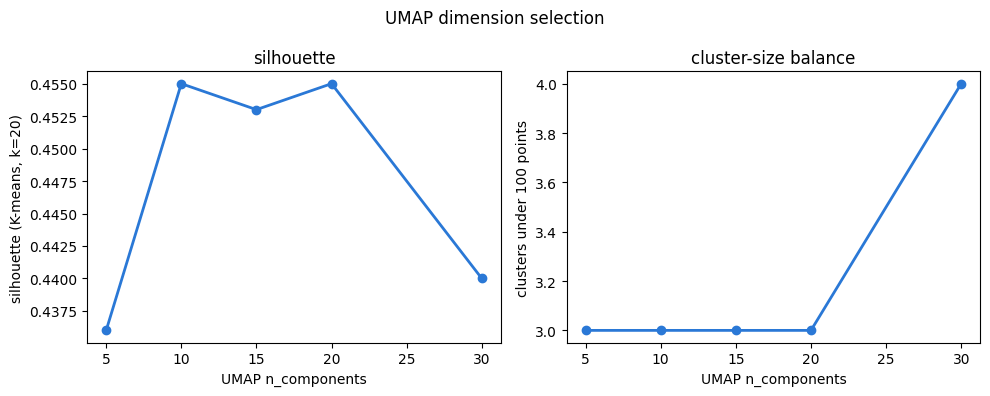

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(results_dim_sweep['n_components'], results_dim_sweep['silhouette'],
             marker='o', color='#2a78d6', linewidth=2)
axes[0].set_xlabel('UMAP n_components')
axes[0].set_ylabel('silhouette (K-means, k=20)')
axes[0].set_title('silhouette')
axes[1].plot(results_dim_sweep['n_components'], results_dim_sweep['n_small_clusters_<100'],
             marker='o', color='#2a78d6', linewidth=2)
axes[1].set_xlabel('UMAP n_components')
axes[1].set_ylabel('clusters under 100 points')
axes[1].set_title('cluster-size balance')
fig.suptitle('UMAP dimension selection')
plt.tight_layout()
plt.show()


10 dimensions gave the best silhouette score (tied with 20) and the best cluster-size balance among the tested values (5, 10, 15, 20, 30), and since it tied with 20 on quality, 10 wins for being simpler and cheaper to compute downstream.

### UMAP Reduction (applied before every model, not just HDBSCAN)

Reduces the 384-dim embeddings to a lower-dimensional space before clustering - high-dimensional Euclidean distance behaves oddly for K-means and Agglomerative too, not just HDBSCAN, so this applies to all three models for a fair comparison. `min_dist=0.0` is UMAP's own recommended setting for clustering use cases (vs. the default 0.1, which is tuned for visualization instead) - lets points pack tightly within a cluster rather than being pushed apart for plotting purposes.

In [6]:
reducer = umap.UMAP(n_components=10, n_neighbors=15, min_dist=0.0, random_state=42, n_jobs=1)  # Choosing n_components=10 from cell above
embedding_reduced = reducer.fit_transform(sample[emb_cols])
print("Reduced embedding shape:", embedding_reduced.shape)


Reduced embedding shape: (30000, 10)


### Shared K-means Sweep Function

Used identically by every Stage 0 feature combination (0a-0e) - same sweep, same
elbow + size-balance review process each time, just pointed at a different `X`.


In [7]:
def run_kmeans_sweep(X, k_range=range(2, 31), silhouette_sample=5000, random_state=42):
    results = []
    label_cache = {}
    for k in k_range:
        km = KMeans(n_clusters=k, random_state=random_state, n_init=10).fit(X)
        score = silhouette_score(X, km.labels_, sample_size=silhouette_sample, random_state=random_state)
        sizes = pd.Series(km.labels_).value_counts()
        results.append({
            'k': k, 'silhouette': round(score, 3),
            'min_cluster_size': int(sizes.min()),
            'n_small_clusters_<100': int((sizes < 100).sum()),
        })
        label_cache[k] = km.labels_
    return pd.DataFrame(results), label_cache


### Stage 0a - K-means, embeddings alone

Baseline: UMAP-reduced embeddings only, no flags, no make/year. K needs choosing -
swept over a wider range this time, tracking BOTH silhouette score AND cluster size
balance at each k, so k can be picked by looking at where the curve bends and where
clusters stay reasonably sized - not just by taking whichever single k has the
highest silhouette (that approach tends to reward K-means for carving off more tiny
outlier groups as k grows, not for finding more meaningful structure - see the k=15
result from before, where 3 of the clusters had only 34-57 points).


In [8]:
X_0a = embedding_reduced
results_0a, labels_0a = run_kmeans_sweep(X_0a)
print(results_0a.to_string(index=False))


 k  silhouette  min_cluster_size  n_small_clusters_<100
 2       0.352              5031                      0
 3       0.293              4770                      0
 4       0.313              4770                      0
 5       0.358              2228                      0
 6       0.371              2228                      0
 7       0.358                57                      1
 8       0.381                57                      1
 9       0.387                57                      1
10       0.413                57                      1
11       0.396                57                      1
12       0.409                51                      2
13       0.425                51                      2
14       0.429                51                      2
15       0.429                34                      3
16       0.447                34                      3
17       0.428                34                      3
18       0.455                34                

Review `results_0a` above before setting `chosen_k_0a` - look for the elbow and watch
`min_cluster_size`/`n_small_clusters_<100`, not just the highest silhouette.


In [9]:
chosen_k_0a = 20  # representative k for the Stage 0 comparison only - the k used for final training is tuned in Stage 1
sample['cluster_0a'] = labels_0a[chosen_k_0a]
print(f"Using k={chosen_k_0a}:")
print(sample['cluster_0a'].value_counts().sort_index())


Using k=20:
cluster_0a
0      570
1     1610
2     1073
3     1207
4     2032
5     2747
6     1423
7     2171
8       51
9     2197
10    1021
11    4485
12    1376
13      57
14      34
15    1278
16     669
17    1526
18    2657
19    1816
Name: count, dtype: int64


### Stage 0b - K-means, embeddings + flags

Adds the 9 severity/equipment flags to Stage 0a's embeddings. Same sweep, same review
process - don't just take the highest silhouette here either.


In [10]:
X_0b = np.hstack([embedding_reduced, sample[flag_cols].values])
results_0b, labels_0b = run_kmeans_sweep(X_0b)
print(results_0b.to_string(index=False))


 k  silhouette  min_cluster_size  n_small_clusters_<100
 2       0.337              5031                      0
 3       0.273              4770                      0
 4       0.289              4770                      0
 5       0.329              2228                      0
 6       0.339              2228                      0
 7       0.337                57                      1
 8       0.343                57                      1
 9       0.347                57                      1
10       0.346                51                      2
11       0.348                51                      2
12       0.360                51                      2
13       0.375                51                      2
14       0.373                51                      2
15       0.352                34                      3
16       0.355                34                      3
17       0.378                34                      3
18       0.374                34                

In [11]:
chosen_k_0b = 20  # placeholder - update after reviewing results_0b
sample['cluster_0b'] = labels_0b[chosen_k_0b]
print(f"Using k={chosen_k_0b}:")
print(sample['cluster_0b'].value_counts().sort_index())


Using k=20:
cluster_0b
0     3492
1     3495
2     1021
3     1078
4     1339
5     1755
6     1307
7       57
8     2565
9     1439
10      51
11    2125
12    1207
13    2821
14     571
15     947
16    1708
17      34
18    2318
19     670
Name: count, dtype: int64


### Stage 0c - K-means, 0b + top-20 make

One-hot encodes the 20 most frequent makes (+ an `Other` bucket for everything else),
added on top of Stage 0b. Watch whether this starts separating clusters mainly by
brand rather than by narrative content - that would be a real, reportable finding on
its own, not just a bad result.


In [12]:
top_makes = sample['mk'].value_counts().head(20).index
make_dummies = pd.get_dummies(
    sample['mk'].where(sample['mk'].isin(top_makes), 'Other'), prefix='Make'
).values.astype(float)

X_0c = np.hstack([embedding_reduced, sample[flag_cols].values, make_dummies])
results_0c, labels_0c = run_kmeans_sweep(X_0c)
print(results_0c.to_string(index=False))


 k  silhouette  min_cluster_size  n_small_clusters_<100
 2       0.307              5031                      0
 3       0.240              4769                      0
 4       0.248              4769                      0
 5       0.282              2228                      0
 6       0.286              2228                      0
 7       0.284                57                      1
 8       0.283                57                      1
 9       0.281                57                      1
10       0.285                51                      2
11       0.281                51                      2
12       0.273                34                      2
13       0.300                51                      2
14       0.290                34                      3
15       0.288                34                      3
16       0.277                34                      3
17       0.297                34                      3
18       0.284                34                

In [13]:
chosen_k_0c = 20  # placeholder - update after reviewing results_0c
sample['cluster_0c'] = labels_0c[chosen_k_0c]
print(f"Using k={chosen_k_0c}:")
print(sample['cluster_0c'].value_counts().sort_index())


Using k=20:
cluster_0c
0     2755
1     2126
2     1024
3     1069
4     2312
5     1610
6     1588
7       57
8     1350
9     1237
10    2287
11    2653
12      34
13    1806
14     672
15     599
16    1204
17    4294
18      51
19    1272
Name: count, dtype: int64


### Stage 0d - K-means, 0b + year

Adds vehicle year as a single numeric feature. Standardized first - raw years
(e.g. 1990-2024) would otherwise dominate the distance calculation purely by scale,
not because year is actually more important than the embeddings or flags.


In [14]:
year_numeric = pd.to_numeric(sample['yr'], errors='coerce')
year_numeric = year_numeric.fillna(year_numeric.median()).values.reshape(-1, 1)
year_scaled = StandardScaler().fit_transform(year_numeric)

X_0d = np.hstack([embedding_reduced, sample[flag_cols].values, year_scaled])
results_0d, labels_0d = run_kmeans_sweep(X_0d)
print(results_0d.to_string(index=False))


 k  silhouette  min_cluster_size  n_small_clusters_<100
 2       0.325              5030                      0
 3       0.256              4770                      0
 4       0.271              4770                      0
 5       0.309              2228                      0
 6       0.322              1064                      0
 7       0.333              1064                      0
 8       0.331                57                      1
 9       0.340                57                      1
10       0.341                51                      2
11       0.346                51                      2
12       0.351                51                      2
13       0.354                51                      2
14       0.351                34                      3
15       0.354                51                      2
16       0.365                34                      3
17       0.345                34                      3
18       0.365                34                

In [15]:
chosen_k_0d = 20  # placeholder - update after reviewing results_0d
sample['cluster_0d'] = labels_0d[chosen_k_0d]
print(f"Using k={chosen_k_0d}:")
print(sample['cluster_0d'].value_counts().sort_index())


Using k=20:
cluster_0d
0     4513
1     1010
2     1054
3     1355
4     1122
5     2555
6     2143
7     2947
8       57
9     1407
10    3114
11     534
12     531
13    2606
14      34
15      51
16    1195
17    1738
18     670
19    1364
Name: count, dtype: int64


### Stage 0e - K-means, 0b + make + year (full combo)

Matches the proposal's literal plan - embeddings combined directly with make and
year. The combination most likely to just rediscover car brands, per the earlier
discussion - worth comparing directly against 0b-0d rather than assuming.


In [16]:
X_0e = np.hstack([embedding_reduced, sample[flag_cols].values, make_dummies, year_scaled])
results_0e, labels_0e = run_kmeans_sweep(X_0e)
print(results_0e.to_string(index=False))


 k  silhouette  min_cluster_size  n_small_clusters_<100
 2       0.298              5046                      0
 3       0.225              4770                      0
 4       0.233              4770                      0
 5       0.266              2228                      0
 6       0.277               820                      0
 7       0.282                57                      1
 8       0.281                57                      1
 9       0.282                57                      1
10       0.278                57                      1
11       0.283                34                      3
12       0.287                51                      2
13       0.279                51                      2
14       0.281                34                      3
15       0.302                51                      2
16       0.302                34                      3
17       0.266                34                      3
18       0.296                51                

In [17]:
chosen_k_0e = 20  # placeholder - update after reviewing results_0e
sample['cluster_0e'] = labels_0e[chosen_k_0e]
print(f"Using k={chosen_k_0e}:")
print(sample['cluster_0e'].value_counts().sort_index())


Using k=20:
cluster_0e
0     2263
1     2606
2     4296
3     2439
4     2205
5      511
6     3028
7     1327
8       57
9     1990
10      51
11    1566
12     277
13    1789
14      34
15     589
16    1056
17     277
18    2967
19     672
Name: count, dtype: int64


### Compare Stages 0a-0e
Plot each stage's silhouette-vs-k sweep together before picking `X_winner`.

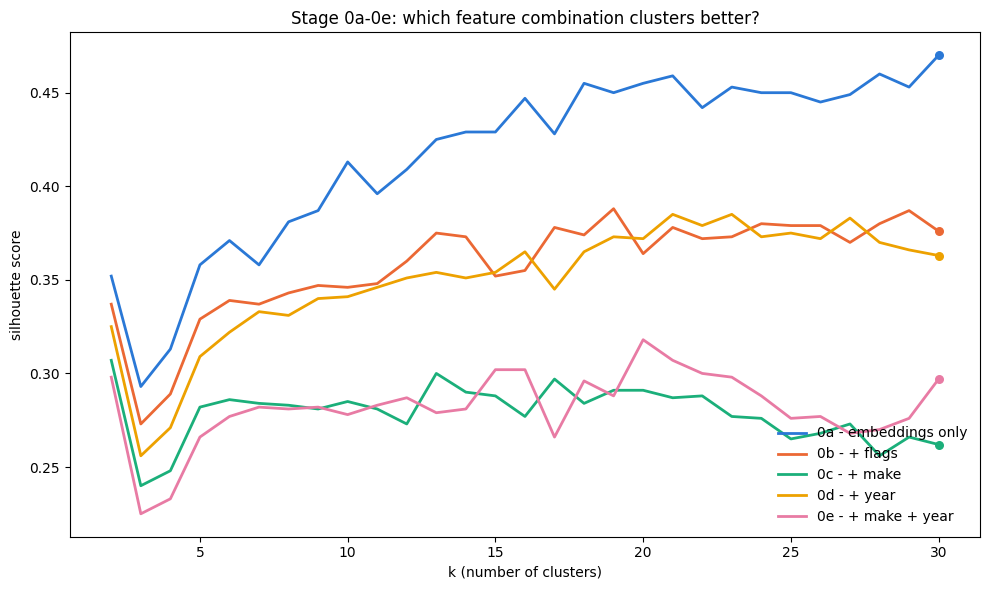

In [18]:
import matplotlib.pyplot as plt

stage_results = {
    '0a - embeddings only': results_0a,
    '0b - + flags': results_0b,
    '0c - + make': results_0c,
    '0d - + year': results_0d,
    '0e - + make + year': results_0e,
}
stage_colors = {
    '0a - embeddings only': '#2a78d6',
    '0b - + flags': '#eb6834',
    '0c - + make': '#1baf7a',
    '0d - + year': '#eda100',
    '0e - + make + year': '#e87ba4',
}

fig, ax = plt.subplots(figsize=(10, 6))
for label, df in stage_results.items():
    ax.plot(df['k'], df['silhouette'], color=stage_colors[label], linewidth=2, label=label)
    ax.scatter(df['k'].iloc[-1], df['silhouette'].iloc[-1], color=stage_colors[label], s=30, zorder=3)

ax.set_xlabel('k (number of clusters)')
ax.set_ylabel('silhouette score')
ax.set_title('Stage 0a-0e: which feature combination clusters better?')
ax.legend(loc='lower right', frameon=False)
plt.tight_layout()
plt.show()

### Stage 0 decision

Pick the winning feature set from 0a-0e above by comparing their size-balanced
elbow points, not raw max silhouette - same reasoning as choosing k. Point
`X_winner` at it; every Stage 1 tuning step below uses it.

In [ ]:
X_winner = X_0a  # X_0a wins


## Stage 1 - Parameter Tuning

Each model's own hyperparameters are tuned here, on the Stage 0 feature set
(`X_winner`). K-means and Agglomerative share the same 30k sample from Stage 0.
HDBSCAN uses its own, larger 150k sample - see 1.2 for why. Every sweep prints a
table and plots it; the value chosen from each is set in a `chosen_*` cell right
after.

### 1.1 K-means: k

`k=20` was picked by eyeballing `results_0a`'s elbow + cluster-size balance on a
single run (`random_state=42`) - that's a judgment call, not a tested one. Testing
whether it's actually the most *reliable* choice: re-fit K-means at a few
candidates near 20, across several random seeds each, and compare how much each
k's silhouette varies run to run. A k that scores well AND consistently (low
spread across seeds) is a stronger choice than one that only looked good on this
one seed.

In [20]:
def run_kmeans_stability(X, k_candidates=(15, 18, 20, 22, 25), seeds=(1, 2, 3, 4, 5), silhouette_sample=5000):
    results = []
    for k in k_candidates:
        scores = []
        for seed in seeds:
            km = KMeans(n_clusters=k, random_state=seed, n_init=10).fit(X)
            score = silhouette_score(X, km.labels_, sample_size=silhouette_sample, random_state=seed)
            scores.append(score)
        scores = np.array(scores)
        results.append({
            'k': k,
            'silhouette_mean': round(scores.mean(), 3),
            'silhouette_std': round(scores.std(), 3),
            'silhouette_min': round(scores.min(), 3),
            'silhouette_max': round(scores.max(), 3),
        })
    return pd.DataFrame(results)

results_k_stability = run_kmeans_stability(X_winner)
print(results_k_stability.to_string(index=False))


 k  silhouette_mean  silhouette_std  silhouette_min  silhouette_max
15            0.423           0.009           0.412           0.434
18            0.444           0.005           0.435           0.449
20            0.456           0.004           0.451           0.462
22            0.454           0.004           0.447           0.458
25            0.458           0.012           0.441           0.478


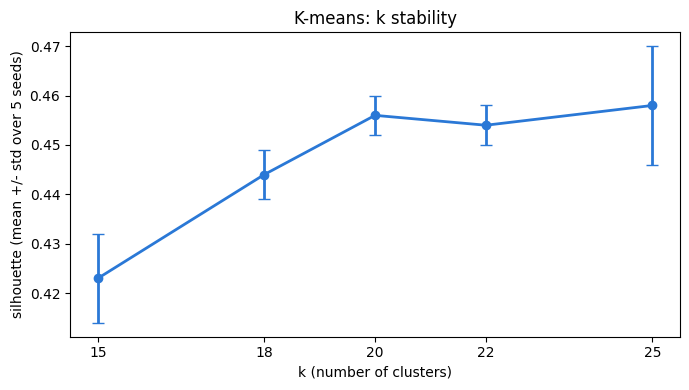

In [21]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(results_k_stability['k'], results_k_stability['silhouette_mean'],
            yerr=results_k_stability['silhouette_std'], marker='o', capsize=4,
            color='#2a78d6', linewidth=2)
ax.set_xticks(results_k_stability['k'])
ax.set_xlabel('k (number of clusters)')
ax.set_ylabel('silhouette (mean +/- std over 5 seeds)')
ax.set_title('K-means: k stability')
plt.tight_layout()
plt.show()


Review `results_k_stability` above - prefer the k with the best combination of
high mean silhouette AND low std (consistent across seeds), not just the highest
single-run score from `results_0a`. Whichever k wins here is `chosen_k_kmeans`
below - it does not need to stay 20.

In [22]:
chosen_k_kmeans = 20  # chosen by reviewing results_k_stability above (best mean silhouette + lowest std)


### 1.2 HDBSCAN: min_cluster_size and min_samples

**Why a 150k sample here, not the shared 30k used for K-means and Agglomerative:**
HDBSCAN's two parameters are count/density settings, so what a given value *means*
depends on how many points are in the data. `min_cluster_size=500` produced 62
clusters on 150k rows but 282 on the full 2.25M (both at `min_samples=10`), so values tuned on a 30k sample
(5x smaller than 150k, 75x smaller than the full dataset) would be calibrated to
the wrong density and wouldn't carry over to the final run. 150k is a compromise:
much closer to full-scale density, still fast (about 30 seconds per fit).
K-means' k and Agglomerative's linkage/`n_clusters` don't have this dependence
(k=20, chosen on 30k, held up on 2.25M: silhouette 0.455 on the sample, 0.440 on
the full data), and Agglomerative's O(n^2) memory makes larger tuning samples
costly.

In [23]:
HDBSCAN_SAMPLE_SIZE = 150000  # bounded, larger than Agglomerative's cap since HDBSCAN
                               # scales better than O(n^2) - but the full 2.25M-row
                               # dataset isn't practical to run directly
hdb_sample = features_unsupervised.sample(min(HDBSCAN_SAMPLE_SIZE, len(features_unsupervised)), random_state=42).reset_index(drop=True)
hdb_embedding_reduced = reducer.transform(hdb_sample[emb_cols])
print("HDBSCAN sample shape:", hdb_sample.shape)


HDBSCAN sample shape: (150000, 398)


#### Sweep `min_cluster_size` (`min_samples` fixed at 10)

`min_cluster_size` is really asking "how many complaints make a reportable
finding?", which shouldn't depend on total dataset size - so it is swept over fixed,
absolute values here rather than scaled with the data (scaling it with n
over-coarsened the clusters: an earlier full-dataset run with `min_cluster_size` scaled
up proportionally to 3,749 gave only 87 clusters, 37.2% noise and DBCV 0.159, vs.
DBCV 0.236 for the fixed value in Stage 2b). Same
review-before-choosing approach as k.

In [24]:
def run_hdbscan_sweep(X, configs, dbcv_sample_size=30000, random_state=42):
    results = []
    dbcv_idx = np.random.RandomState(random_state).choice(len(X), size=min(dbcv_sample_size, len(X)), replace=False)
    for mcs, ms in configs:
        labels = hdbscan.HDBSCAN(min_cluster_size=mcs, min_samples=ms, core_dist_n_jobs=-1).fit(X).labels_
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        n_noise = int((labels == -1).sum())
        dbcv = validity_index(X[dbcv_idx].astype(np.float64), labels[dbcv_idx])
        results.append({
            'min_cluster_size': mcs,
            'min_samples': ms,
            'n_clusters': n_clusters,
            'noise_rate': round(n_noise / len(labels), 3),
            'dbcv': round(dbcv, 3),
        })
    return pd.DataFrame(results)

def plot_hdbscan_sweep(df, x_col, title):
    fig, axes = plt.subplots(1, 3, figsize=(14, 4))
    for ax, (col, label) in zip(axes, [('n_clusters', 'cluster count'), ('noise_rate', 'noise rate'), ('dbcv', 'DBCV')]):
        ax.plot(df[x_col], df[col], marker='o', color='#7B5EA7', linewidth=2)
        ax.set_xlabel(x_col)
        ax.set_ylabel(label)
        ax.set_title(label)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

results_hdb_sweep = run_hdbscan_sweep(hdb_embedding_reduced, [(mcs, 10) for mcs in (200, 500, 1000, 2000)])
print(results_hdb_sweep.to_string(index=False))


 min_cluster_size  min_samples  n_clusters  noise_rate  dbcv
              200           10         122       0.383 0.171
              500           10          62       0.326 0.163
             1000           10          31       0.269 0.156
             2000           10          17       0.236 0.149


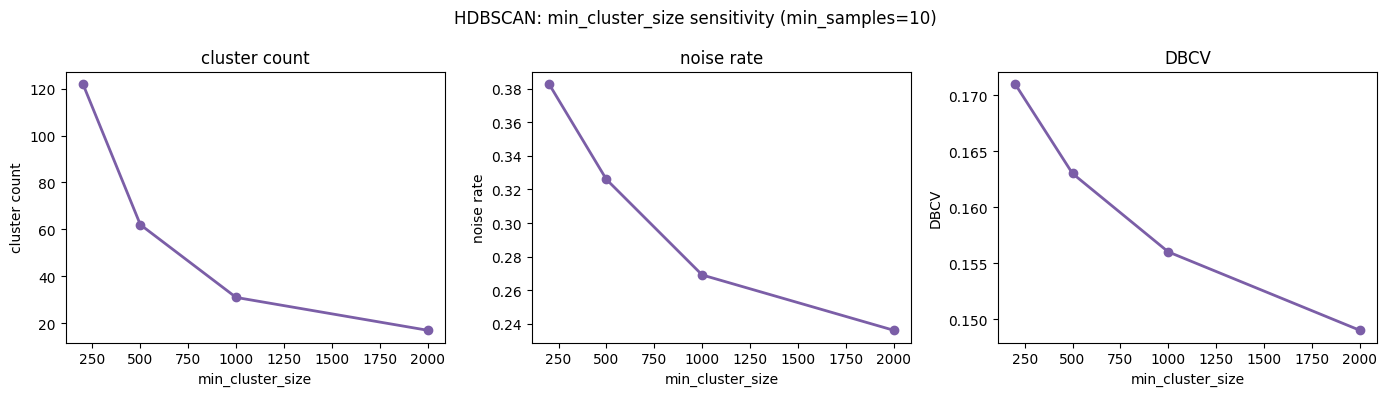

In [25]:
plot_hdbscan_sweep(results_hdb_sweep, 'min_cluster_size', 'HDBSCAN: min_cluster_size sensitivity (min_samples=10)')


Review `results_hdb_sweep` above - look for the best balance of cluster count, noise
rate, and DBCV, not just the highest DBCV (same reasoning as `chosen_k_0a` - don't
just take the max).

In [26]:
chosen_min_cluster_size_hdb = 500  # chosen by reviewing results_hdb_sweep above


#### Sweep `min_samples` (`min_cluster_size` held at the chosen value)

`min_samples` controls how conservative the density estimate is - higher values
label more points as noise. It was fixed at 10 on reasoning alone (it's a local
density setting, so it shouldn't scale with dataset size); this tests the value
directly instead of assuming it.

In [27]:
results_hdb_ms_sweep = run_hdbscan_sweep(hdb_embedding_reduced, [(chosen_min_cluster_size_hdb, ms) for ms in (5, 10, 15, 25)])
print(results_hdb_ms_sweep.to_string(index=False))


 min_cluster_size  min_samples  n_clusters  noise_rate  dbcv
              500            5          64       0.354 0.151
              500           10          62       0.326 0.163
              500           15          56       0.321 0.166
              500           25          59       0.319 0.176


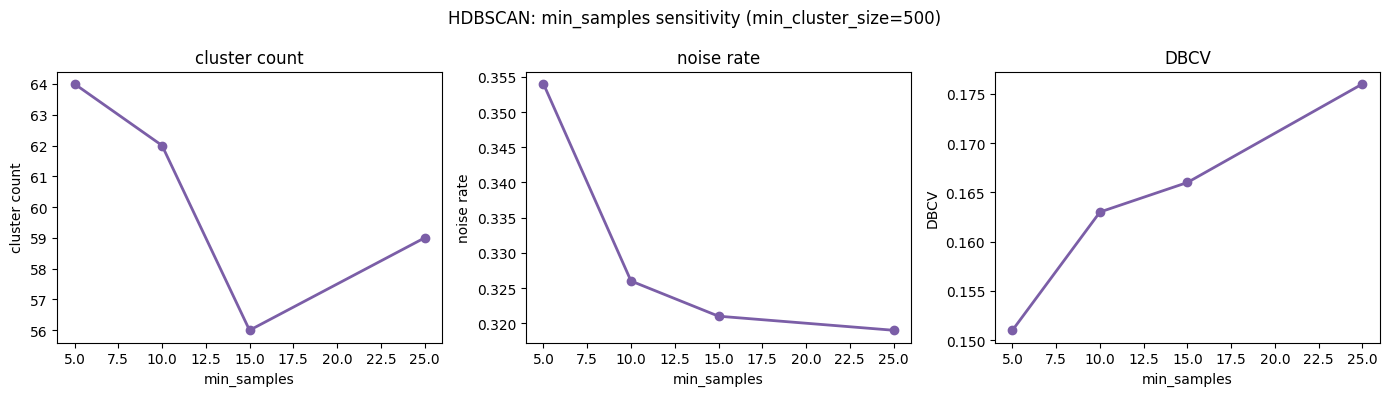

In [28]:
plot_hdbscan_sweep(results_hdb_ms_sweep, 'min_samples', f'HDBSCAN: min_samples sensitivity (min_cluster_size={chosen_min_cluster_size_hdb})')


Review `results_hdb_ms_sweep` above - same balance-not-max logic as every other
choice here.

In [29]:
chosen_min_samples_hdb = 25  # best DBCV (0.176) and lowest noise (31.9%) of {5,10,15,25}; cluster count stays flat (56-64), so no trade-off against interpretability


### 1.3 Agglomerative: linkage and n_clusters

Uses the same shared 30k sample as K-means. Until now Agglomerative just borrowed
K-means' k with no tuning of its own; here it gets two independent choices.

**Step 1 - linkage** (how the distance between two clusters is measured when
merging): compared at a fixed reference `n_clusters=20` to isolate the linkage
effect. The lopsided cluster sizes seen so far with the default `ward` linkage are
what this checks - `single` linkage in particular is known to chain points into
one huge cluster, so the size-imbalance column matters as much as silhouette.

**Step 2 - n_clusters**, for the winning linkage, from a single full-tree fit: the
silhouette at each cut, plus the merge distance (a large jump in merge distance is
the hierarchical equivalent of an elbow).

In [30]:
def agglo_linkage_matrix(model):
    counts = np.zeros(model.children_.shape[0])
    n_samples = len(model.labels_)
    for i, merge in enumerate(model.children_):
        current_count = 0
        for child_idx in merge:
            current_count += 1 if child_idx < n_samples else counts[child_idx - n_samples]
        counts[i] = current_count
    return np.column_stack([model.children_, model.distances_, counts]).astype(float)

def run_agglo_linkage_sweep(X, linkages=('ward', 'average', 'complete', 'single'), n_clusters=20,
                             silhouette_sample=5000, random_state=42):
    results = []
    for linkage in linkages:
        labels = AgglomerativeClustering(n_clusters=n_clusters, linkage=linkage).fit(X).labels_
        sizes = np.bincount(labels)
        score = silhouette_score(X, labels, sample_size=silhouette_sample, random_state=random_state)
        results.append({
            'linkage': linkage, 'silhouette': round(score, 3),
            'min_cluster_size': int(sizes.min()), 'max_cluster_size': int(sizes.max()),
            'size_ratio': round(sizes.max() / sizes.min(), 1),
            'n_small_clusters_<100': int((sizes < 100).sum()),
        })
    return pd.DataFrame(results)

results_agglo_linkage = run_agglo_linkage_sweep(X_winner)  # n_clusters=20 is a fixed reference here; n_clusters is tuned next
print(results_agglo_linkage.to_string(index=False))


 linkage  silhouette  min_cluster_size  max_cluster_size  size_ratio  n_small_clusters_<100
    ward       0.436                34              4334       127.5                      3
 average       0.447                12              6661       555.1                      6
complete       0.373                12              6438       536.5                      6
  single      -0.227                 1             26570     26570.0                     16


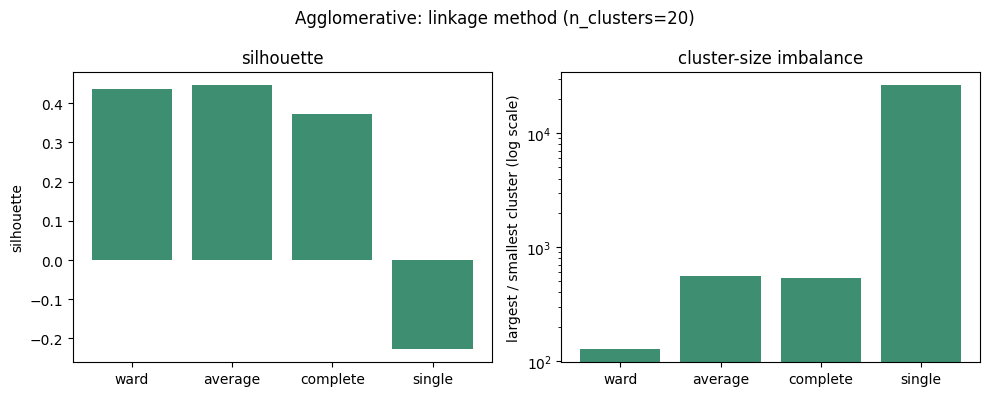

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].bar(results_agglo_linkage['linkage'], results_agglo_linkage['silhouette'], color='#3E8E72')
axes[0].set_ylabel('silhouette')
axes[0].set_title('silhouette')
axes[1].bar(results_agglo_linkage['linkage'], results_agglo_linkage['size_ratio'], color='#3E8E72')
axes[1].set_yscale('log')
axes[1].set_ylabel('largest / smallest cluster (log scale)')
axes[1].set_title('cluster-size imbalance')
fig.suptitle('Agglomerative: linkage method (n_clusters=20)')
plt.tight_layout()
plt.show()


Review `results_agglo_linkage` above - weigh silhouette against the size-imbalance
column, not silhouette alone (a linkage can score well by lumping almost everything
into one cluster).

In [32]:
chosen_linkage = 'ward'  # most balanced of the four (size ratio 127 vs 536-555 for complete/average; single is degenerate, silhouette -0.227); average's +0.011 silhouette doesn't justify ~4x worse imbalance


In [33]:
def run_agglo_n_clusters_sweep(X, linkage, n_range=range(5, 41), silhouette_sample=5000, random_state=42):
    model = AgglomerativeClustering(n_clusters=None, distance_threshold=0, linkage=linkage).fit(X)
    Z = agglo_linkage_matrix(model)
    results = []
    for n in n_range:
        labels = fcluster(Z, t=n, criterion='maxclust') - 1
        sizes = np.bincount(labels)
        score = silhouette_score(X, labels, sample_size=silhouette_sample, random_state=random_state)
        results.append({
            'n_clusters': n, 'silhouette': round(score, 3),
            'min_cluster_size': int(sizes.min()),
            'n_small_clusters_<100': int((sizes < 100).sum()),
            'merge_distance': round(Z[-(n - 1), 2], 3),
        })
    return pd.DataFrame(results)

results_agglo_n = run_agglo_n_clusters_sweep(X_winner, chosen_linkage)
print(results_agglo_n.to_string(index=False))


 n_clusters  silhouette  min_cluster_size  n_small_clusters_<100  merge_distance
          5       0.352              2228                      0         233.825
          6       0.367              2228                      0         209.375
          7       0.375               108                      0         190.125
          8       0.360               108                      0         151.400
          9       0.361                51                      2         128.814
         10       0.376                51                      2         122.921
         11       0.381                51                      2         111.750
         12       0.405                51                      2         111.728
         13       0.409                34                      3         111.292
         14       0.419                34                      3         105.448
         15       0.421                34                      3          88.489
         16       0.433     

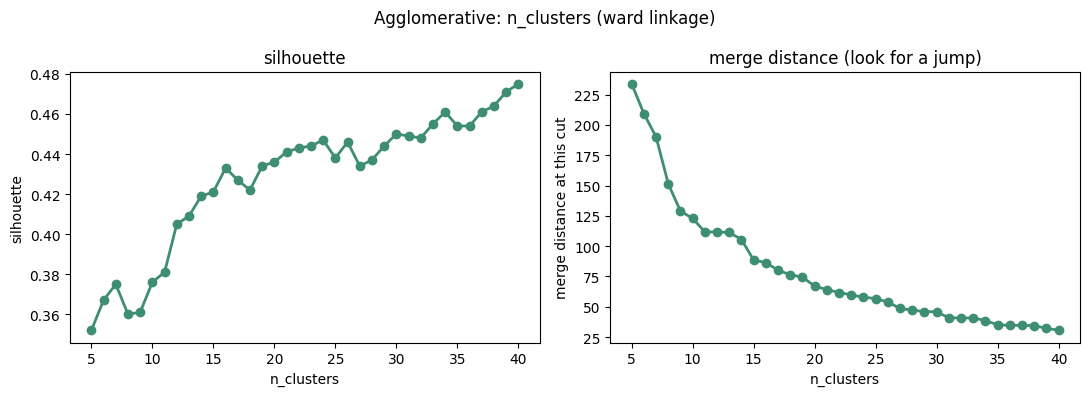

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(results_agglo_n['n_clusters'], results_agglo_n['silhouette'], marker='o', color='#3E8E72', linewidth=2)
axes[0].set_xlabel('n_clusters')
axes[0].set_ylabel('silhouette')
axes[0].set_title('silhouette')
axes[1].plot(results_agglo_n['n_clusters'], results_agglo_n['merge_distance'], marker='o', color='#3E8E72', linewidth=2)
axes[1].set_xlabel('n_clusters')
axes[1].set_ylabel('merge distance at this cut')
axes[1].set_title('merge distance (look for a jump)')
fig.suptitle(f'Agglomerative: n_clusters ({chosen_linkage} linkage)')
plt.tight_layout()
plt.show()


Review `results_agglo_n` above - look for where silhouette levels off and merge
distance jumps, and watch `min_cluster_size` / `n_small_clusters_<100`, not just the
highest silhouette.

In [35]:
chosen_n_clusters_agglo = 20  # silhouette plateaus at ~0.43-0.44 from n=16-21; past n=22 the gains come from splitting off 12-15 point clusters. 20 sits in the plateau (21's +0.005 is within noise)


## Stage 2 - Full-Dataset Training

Train each model's final version using the Stage 0 feature set and the Stage 1
parameter choices (`chosen_k_kmeans`; `chosen_min_cluster_size_hdb` and
`chosen_min_samples_hdb`; `chosen_linkage` and `chosen_n_clusters_agglo`). K-means
and HDBSCAN run on the full dataset. Agglomerative is O(n^2) in time and memory (a
full pairwise distance matrix - roughly 10GB at 50k rows), so it runs on a 50k-row
sample instead.

In [36]:
embedding_reduced_full = reducer.transform(features_unsupervised[emb_cols])
print("Full reduced embedding shape:", embedding_reduced_full.shape)

Full reduced embedding shape: (2249816, 10)


### 2a - K-means (full dataset)

In [37]:
kmeans_final = KMeans(n_clusters=chosen_k_kmeans, random_state=42, n_init=10).fit(embedding_reduced_full)
features_unsupervised['cluster_kmeans'] = kmeans_final.labels_

score_kmeans_final = silhouette_score(embedding_reduced_full, kmeans_final.labels_, sample_size=5000, random_state=42)
print(f"K-means (k={chosen_k_kmeans}) silhouette: {score_kmeans_final:.3f}")
print(features_unsupervised['cluster_kmeans'].value_counts().sort_index())

K-means (k=20) silhouette: 0.440
cluster_kmeans
0      50884
1      44652
2     162246
3     195369
4     117578
5      91954
6     199828
7     208671
8      82200
9     128004
10     73846
11    229250
12    100420
13      4761
14    136100
15    151970
16      2845
17    104113
18    162481
19      2644
Name: count, dtype: int64


### 2b - HDBSCAN (full dataset, standalone `hdbscan` package)

Applies the parameters tuned in Stage 1.2 (on a 150k sample) to the full dataset,
unscaled. Uses the standalone `hdbscan` package rather than sklearn's port, which
did not finish a full-dataset run in over an hour.

In [52]:
hdb_final = hdbscan.HDBSCAN(min_cluster_size=chosen_min_cluster_size_hdb, min_samples=chosen_min_samples_hdb, core_dist_n_jobs=-1).fit(embedding_reduced_full)
labels_hdb_final = hdb_final.labels_
features_unsupervised['cluster_hdbscan'] = labels_hdb_final

n_clusters_final = len(set(labels_hdb_final)) - (1 if -1 in labels_hdb_final else 0)
n_noise_final = int((labels_hdb_final == -1).sum())
print(f"Using min_cluster_size={chosen_min_cluster_size_hdb}, min_samples={chosen_min_samples_hdb} on the full dataset:")
print(f"Clusters found: {n_clusters_final}")
print(f"Noise points: {n_noise_final} ({n_noise_final/len(labels_hdb_final):.1%})")

dbcv_idx = np.random.RandomState(42).choice(len(embedding_reduced_full), size=30000, replace=False)
dbcv_score_final = validity_index(embedding_reduced_full[dbcv_idx].astype(np.float64), labels_hdb_final[dbcv_idx])
print(f"DBCV (30k-point subsample): {dbcv_score_final:.3f}")


Using min_cluster_size=500, min_samples=25 on the full dataset:
Clusters found: 278
Noise points: 976671 (43.4%)
DBCV (30k-point subsample): 0.253


### 2c - Agglomerative (50k sample - full dataset is infeasible)

Ward at 50k rows needs roughly 10GB for the pairwise distance matrix; if a
different linkage wins in Stage 1.3, check memory before running.

In [53]:
AGGLO_SAMPLE_SIZE = 50000  # bounded - Agglomerative is O(n^2) in time and memory
agglo_sample = features_unsupervised.sample(min(AGGLO_SAMPLE_SIZE, len(features_unsupervised)), random_state=42).reset_index(drop=True)
agglo_embedding_reduced = reducer.transform(agglo_sample[emb_cols])

agglo_final = AgglomerativeClustering(n_clusters=chosen_n_clusters_agglo, linkage=chosen_linkage, compute_distances=True).fit(agglo_embedding_reduced)
agglo_sample['cluster_agglo'] = agglo_final.labels_

score_agglo_final = silhouette_score(agglo_embedding_reduced, agglo_final.labels_, sample_size=5000, random_state=42)
print(f"Agglomerative (n={chosen_n_clusters_agglo}, linkage={chosen_linkage}, {len(agglo_sample)} rows) silhouette: {score_agglo_final:.3f}")
print(agglo_sample['cluster_agglo'].value_counts().sort_index())


Agglomerative (n=20, linkage=ward, 50000 rows) silhouette: 0.435
cluster_agglo
0     4682
1     5742
2     3293
3       71
4     6667
5     2420
6     2611
7     3027
8     3396
9     2467
10    2035
11    3580
12      53
13    1794
14    1818
15    1088
16     949
17    2909
18    1298
19     100
Name: count, dtype: int64


## Stage 3 - Validation (recall-rate per cluster)

The real cross-model comparison metric, not silhouette/DBCV. A complaint counts as **later recalled** if its (make, model, year) has at least one recall campaign dated after the complaint's `DATEA` - the same join key used throughout (mk, md, yr), just read forward from the complaint instead of backward from the campaign. No lookback window cap is applied here (same reasoning as deferring the window choice from `02`: cheap to filter further later, expensive to recompute).

Clusters with very few complaints can show misleadingly extreme recall rates - only trust rates computed over a reasonable number of complaints (`n_complaints` is printed alongside each rate).

In [54]:
recall_df = pd.read_csv('data/df_recalls_keep_multilabel.csv', low_memory=False)
recall_df['RCDATE'] = pd.to_datetime(recall_df['RCDATE'])

max_recall_date = (
    recall_df.dropna(subset=['RCDATE'])
    .groupby(['mk', 'md', 'yr'])['RCDATE']
    .max()
    .rename('max_recall_date')
)

features_unsupervised = features_unsupervised.drop(columns=['max_recall_date', 'was_later_recalled'], errors='ignore')  # safe to re-run
features_unsupervised = features_unsupervised.merge(max_recall_date, on=['mk', 'md', 'yr'], how='left')
features_unsupervised['was_later_recalled'] = (
    features_unsupervised['max_recall_date'].notna()
    & (features_unsupervised['max_recall_date'] > features_unsupervised['DATEA'])
)

baseline_recall_rate = features_unsupervised['was_later_recalled'].mean()
print(f"Baseline recall rate (all complaints): {baseline_recall_rate:.1%}")

Baseline recall rate (all complaints): 43.7%


In [55]:
def recall_rate_table(df, cluster_col):
    g = df.groupby(cluster_col)['was_later_recalled'].agg(['mean', 'count'])
    g = g.rename(columns={'mean': 'recall_rate', 'count': 'n_complaints'})
    return g.sort_values('recall_rate', ascending=False)

print(f"K-means cluster recall rates (baseline = {baseline_recall_rate:.1%}):")
print(recall_rate_table(features_unsupervised, 'cluster_kmeans').to_string())

K-means cluster recall rates (baseline = 43.7%):
                recall_rate  n_complaints
cluster_kmeans                           
1                  0.759697         44652
8                  0.592372         82200
0                  0.578767         50884
18                 0.575600        162481
12                 0.548038        100420
7                  0.519713        208671
17                 0.488556        104113
5                  0.463558         91954
10                 0.445589         73846
11                 0.443586        229250
3                  0.435617        195369
15                 0.406699        151970
14                 0.405981        136100
19                 0.372163          2644
6                  0.344887        199828
2                  0.336705        162246
4                  0.250931        117578
9                  0.224696        128004
16                 0.123023          2845
13                 0.115522          4761


In [56]:
print(f"HDBSCAN cluster recall rates (baseline = {baseline_recall_rate:.1%}):")
print(recall_rate_table(features_unsupervised, 'cluster_hdbscan').to_string())


HDBSCAN cluster recall rates (baseline = 43.7%):
                 recall_rate  n_complaints
cluster_hdbscan                           
 245                0.962329          1460
 195                0.950904          4094
 43                 0.923773           774
 74                 0.910529          2213
 122                0.905263           570
 197                0.901952          2356
 56                 0.899522           836
 36                 0.897994          4137
 57                 0.895937          4036
 196                0.889179           767
 105                0.871411          3204
 191                0.870107           562
 75                 0.839763          1011
 45                 0.818535          2061
 214                0.811611          1688
 109                0.804745          1096
 137                0.794000           500
 83                 0.790713          4587
 80                 0.788745          2310
 44                 0.785280         16291
 186 

In [57]:
# Agglomerative ran on its own capped sample, so the linkage is recomputed for it here
agglo_sample = agglo_sample.drop(columns=['max_recall_date', 'was_later_recalled'], errors='ignore')  # safe to re-run
agglo_sample = agglo_sample.merge(max_recall_date, on=['mk', 'md', 'yr'], how='left')
agglo_sample['was_later_recalled'] = (
    agglo_sample['max_recall_date'].notna()
    & (agglo_sample['max_recall_date'] > agglo_sample['DATEA'])
)

agglo_baseline = agglo_sample['was_later_recalled'].mean()
print(f"Agglomerative cluster recall rates (baseline = {agglo_baseline:.1%}):")
print(recall_rate_table(agglo_sample, 'cluster_agglo').to_string())

Agglomerative cluster recall rates (baseline = 44.1%):
               recall_rate  n_complaints
cluster_agglo                           
16                0.761855           949
15                0.608456          1088
13                0.596990          1794
2                 0.580322          3293
14                0.521452          1818
7                 0.508755          3027
4                 0.485976          6667
0                 0.481205          4682
9                 0.480746          2467
18                0.477658          1298
5                 0.449587          2420
12                0.433962            53
17                0.408732          2909
8                 0.381920          3396
1                 0.347788          5742
11                0.328492          3580
6                 0.260437          2611
10                0.221622          2035
3                 0.112676            71
19                0.110000           100


## Visualizations for Report

The tuning (sensitivity) charts sit in Stage 1, next to the tables they plot. This
section holds the result charts: recall rate per cluster for each model, the
Agglomerative dendrogram, and a shared 2D view. Colors are fixed per model across
every chart: K-means blue (`#2a78d6`), HDBSCAN purple (`#7B5EA7`), Agglomerative
green (`#3E8E72`).

### K-means

The tuning chart is the k-stability plot in Stage 1.1, and the feature comparison
is in Stage 0. Below: recall rate per K-means cluster.

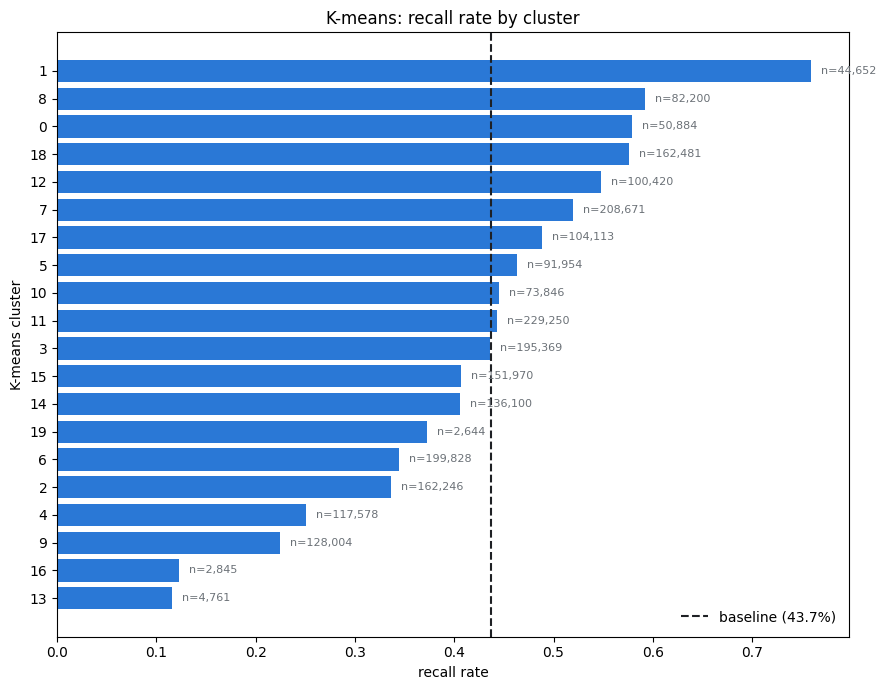

In [58]:
import matplotlib.pyplot as plt

kmeans_table = recall_rate_table(features_unsupervised, 'cluster_kmeans')

fig, ax = plt.subplots(figsize=(9, 7))
bars = ax.barh(kmeans_table.index.astype(str), kmeans_table['recall_rate'], color='#2a78d6')
ax.axvline(baseline_recall_rate, color='#1E2024', linestyle='--', linewidth=1.5,
           label=f'baseline ({baseline_recall_rate:.1%})')
ax.invert_yaxis()
ax.set_xlabel('recall rate')
ax.set_ylabel('K-means cluster')
ax.set_title('K-means: recall rate by cluster')
for bar, n in zip(bars, kmeans_table['n_complaints']):
    ax.text(bar.get_width() + 0.01, bar.get_y() + bar.get_height() / 2, f'n={n:,}',
            va='center', fontsize=8, color='#6B7177')
ax.legend(loc='lower right', frameon=False)
plt.tight_layout()
plt.show()


### HDBSCAN

The tuning charts (`min_cluster_size` and `min_samples` sensitivity) are in Stage
1.2. Below: recall rate for the top clusters, with the noise bucket shown
separately for comparison.

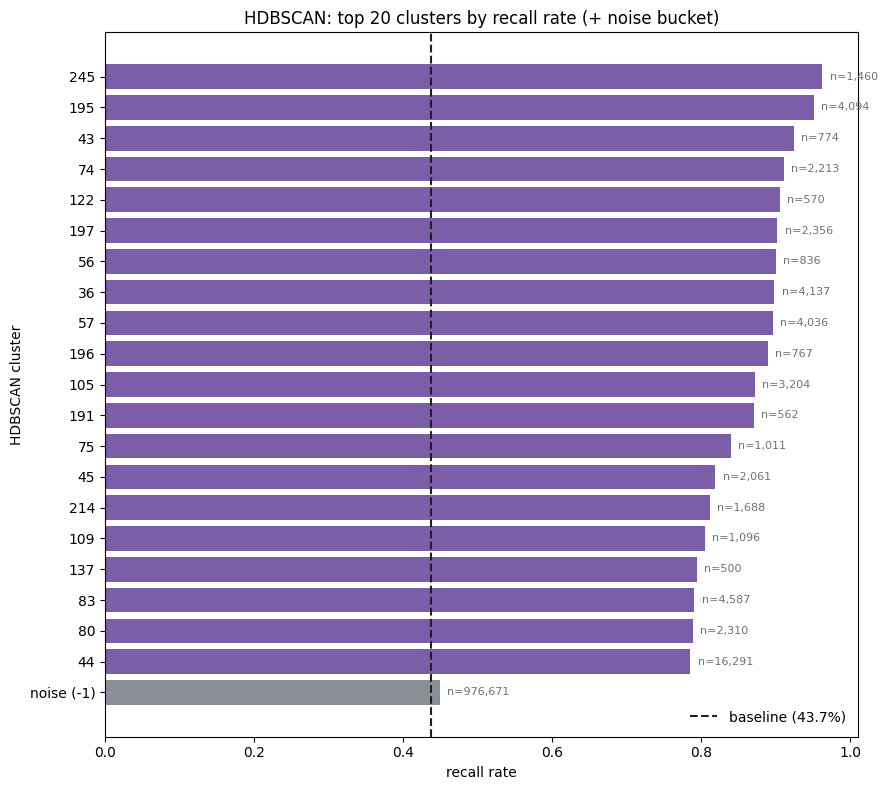

In [59]:
hdb_table = recall_rate_table(features_unsupervised, 'cluster_hdbscan')
top_n = 20
hdb_top = hdb_table[hdb_table.index != -1].head(top_n)

fig, ax = plt.subplots(figsize=(9, 8))
bars = ax.barh(hdb_top.index.astype(str), hdb_top['recall_rate'], color='#7B5EA7')
if -1 in hdb_table.index:
    noise_rate = hdb_table.loc[-1, 'recall_rate']
    noise_n = hdb_table.loc[-1, 'n_complaints']
    ax.barh(['noise (-1)'], [noise_rate], color='#8A8F96')
    ax.text(noise_rate + 0.01, len(hdb_top), f'n={noise_n:,}', va='center', fontsize=8, color='#6B7177')
ax.axvline(baseline_recall_rate, color='#1E2024', linestyle='--', linewidth=1.5,
           label=f'baseline ({baseline_recall_rate:.1%})')
ax.invert_yaxis()
ax.set_xlabel('recall rate')
ax.set_ylabel('HDBSCAN cluster')
ax.set_title(f'HDBSCAN: top {top_n} clusters by recall rate (+ noise bucket)')
for bar, n in zip(bars, hdb_top['n_complaints']):
    ax.text(bar.get_width() + 0.01, bar.get_y() + bar.get_height() / 2, f'n={n:,}',
            va='center', fontsize=8, color='#6B7177')
ax.legend(loc='lower right', frameon=False)
plt.tight_layout()
plt.show()


### Agglomerative

The tuning charts (linkage and `n_clusters`) are in Stage 1.3. Below: a truncated
dendrogram (last 30 merges) showing the hierarchical structure the cut was taken
from, and recall rate per cluster, with clusters under 200 complaints greyed out
as low-confidence rather than real findings.

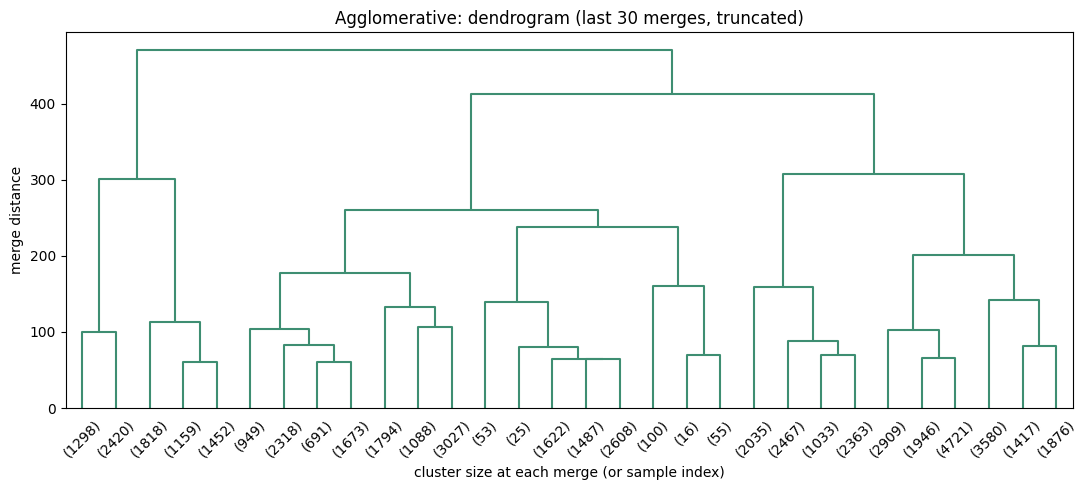

In [60]:
fig, ax = plt.subplots(figsize=(11, 5))
dendrogram(agglo_linkage_matrix(agglo_final), truncate_mode='lastp', p=30, ax=ax,
           color_threshold=0, above_threshold_color='#3E8E72')
ax.set_title('Agglomerative: dendrogram (last 30 merges, truncated)')
ax.set_xlabel('cluster size at each merge (or sample index)')
ax.set_ylabel('merge distance')
plt.tight_layout()
plt.show()


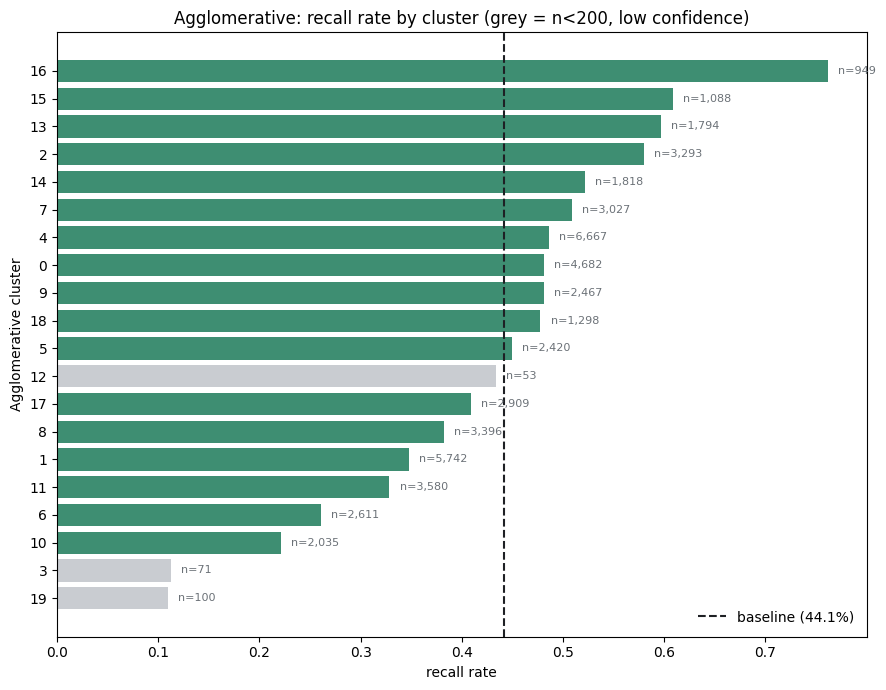

In [61]:
agglo_table = recall_rate_table(agglo_sample, 'cluster_agglo')
low_confidence = agglo_table['n_complaints'] < 200

fig, ax = plt.subplots(figsize=(9, 7))
colors = ['#C9CCD1' if flag else '#3E8E72' for flag in low_confidence]
bars = ax.barh(agglo_table.index.astype(str), agglo_table['recall_rate'], color=colors)
ax.axvline(agglo_baseline, color='#1E2024', linestyle='--', linewidth=1.5,
           label=f'baseline ({agglo_baseline:.1%})')
ax.invert_yaxis()
ax.set_xlabel('recall rate')
ax.set_ylabel('Agglomerative cluster')
ax.set_title('Agglomerative: recall rate by cluster (grey = n<200, low confidence)')
for bar, n in zip(bars, agglo_table['n_complaints']):
    ax.text(bar.get_width() + 0.01, bar.get_y() + bar.get_height() / 2, f'n={n:,}',
            va='center', fontsize=8, color='#6B7177')
ax.legend(loc='lower right', frameon=False)
plt.tight_layout()
plt.show()


### Shared 2D view: where do high-risk clusters sit in embedding space?

A categorical scatter colored by raw cluster ID doesn't work here - 282 HDBSCAN
clusters is far more than a human eye can tell apart by hue, and even 20 pushes
it. Instead: one 2D UMAP projection (separate from the 10D clustering projection -
`min_dist=0.1`, tuned for visualization, not `0.0`), built once on the
Agglomerative sample (which already carries all three models' cluster
assignments), then colored three ways - once per model - by each point's *own
cluster's recall rate* on a shared sequential colormap (light = low risk, dark =
high risk). This sidesteps the color-count problem entirely regardless of cluster
count, and keeps the three panels visually comparable since they share identical
point positions.

This 2D view is for illustration only, not proof of the clustering geometry. The cluster labels come from the real 10D clustering space (min_dist=0.0, optimized for density/distance-based clustering); the 2D positions come from a separate UMAP projection fit independently on the original 384-dim embeddings (min_dist=0.1, tuned for visualization). Because these are two different low-dimensional compressions of the same high-dimensional data, two points that appear close or far apart in this 2D plot aren't guaranteed to have been close or far apart in the space the algorithms actually clustered on. The real validation of cluster quality is the silhouette/DBCV scores (computed in the true 10D clustering space) and the recall-rate-per-cluster results (computed from the real cluster labels) — this chart is a supplementary qualitative aid, not a substitute for those.

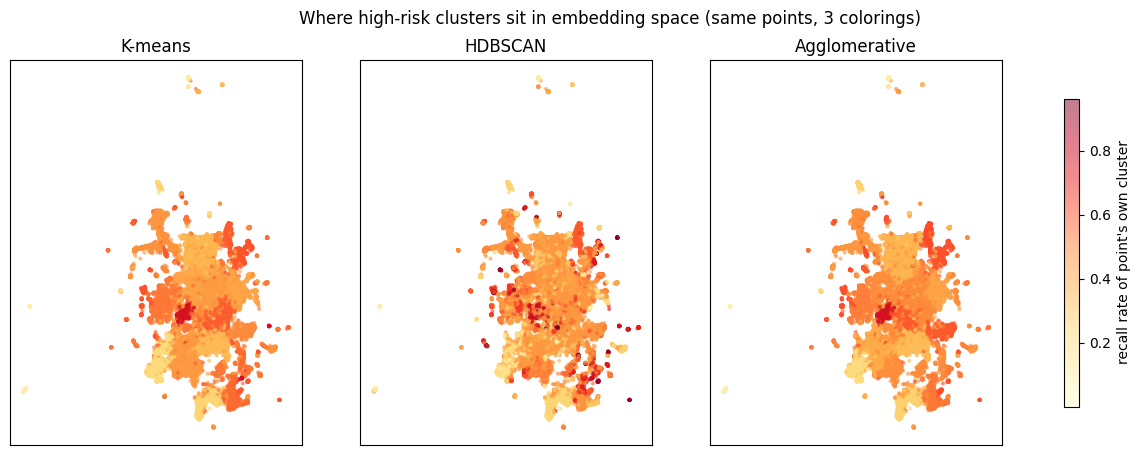

In [62]:
viz_reducer = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1, random_state=42, n_jobs=1)
viz_embedding = viz_reducer.fit_transform(agglo_sample[emb_cols])

agglo_sample['recall_rate_kmeans'] = agglo_sample['cluster_kmeans'].map(kmeans_table['recall_rate'])
agglo_sample['recall_rate_hdbscan'] = agglo_sample['cluster_hdbscan'].map(hdb_table['recall_rate'])
agglo_sample['recall_rate_agglo'] = agglo_sample['cluster_agglo'].map(agglo_table['recall_rate'])

panels = [
    ('recall_rate_kmeans', 'K-means'),
    ('recall_rate_hdbscan', 'HDBSCAN'),
    ('recall_rate_agglo', 'Agglomerative'),
]
vmin = min(agglo_sample[c].min() for c, _ in panels)
vmax = max(agglo_sample[c].max() for c, _ in panels)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (col, title) in zip(axes, panels):
    sc = ax.scatter(viz_embedding[:, 0], viz_embedding[:, 1], c=agglo_sample[col],
                     cmap='YlOrRd', vmin=vmin, vmax=vmax, s=4, alpha=0.5)
    ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks([])

fig.colorbar(sc, ax=axes, label="recall rate of point's own cluster", shrink=0.8)
fig.suptitle('Where high-risk clusters sit in embedding space (same points, 3 colorings)')
plt.show()
